## 1. Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import html
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix, hstack

In [2]:
df = pd.read_csv('anime.csv')
df.head()

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266


## 2. Explore the data

In [3]:
print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())
df.info()

Dataset shape: (12294, 7)
Columns: ['anime_id', 'name', 'genre', 'type', 'episodes', 'rating', 'members']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  object 
 2   genre     12232 non-null  object 
 3   type      12269 non-null  object 
 4   episodes  12294 non-null  object 
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 672.5+ KB


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
anime_id,12294.0,NaN,NaN,NaN,14058.221653,11455.294701,1.0,3484.25,10260.5,24794.5,34527.0
name,12294,12292,Shi Wan Ge Leng Xiaohua,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genre,12232,3264,Hentai,823,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,12269,6,TV,3787,NaN,NaN,NaN,NaN,NaN,NaN,NaN
episodes,12294,187,1,5677,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,12064.0,NaN,NaN,NaN,6.473902,1.026746,1.67,5.88,6.57,7.18,10.0
members,12294.0,NaN,NaN,NaN,18071.338864,54820.676925,5.0,225.0,1550.0,9437.0,1013917.0


In [5]:
df.isnull().sum()

anime_id      0
name          0
genre        62
type         25
episodes      0
rating      230
members       0
dtype: int64

In [6]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate anime IDs:', df['anime_id'].duplicated().sum())

Duplicate rows: 0
Duplicate anime IDs: 0


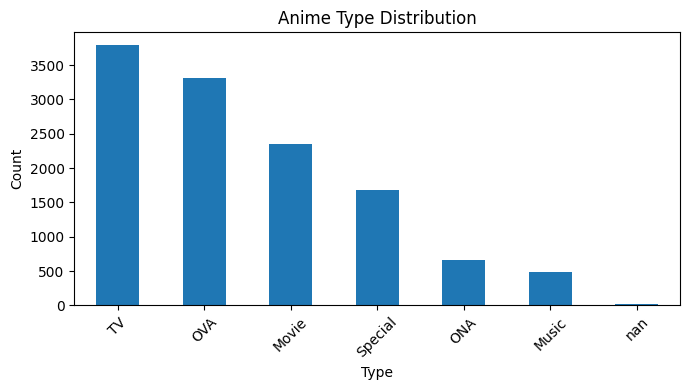

In [7]:
plt.figure(figsize=(7, 4))
df['type'].value_counts(dropna=False).plot(kind='bar')
plt.title('Anime Type Distribution')
plt.xlabel('Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

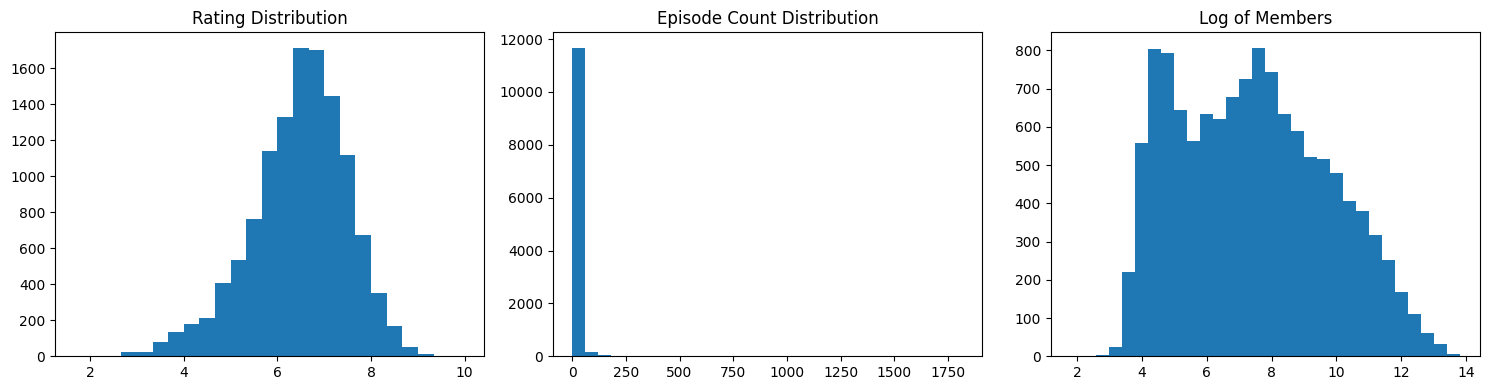

In [8]:
df['episodes_numeric'] = pd.to_numeric(df['episodes'].replace('Unknown', np.nan), errors='coerce')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df['rating'].dropna(), bins=25)
axes[0].set_title('Rating Distribution')
axes[1].hist(df['episodes_numeric'].dropna(), bins=30)
axes[1].set_title('Episode Count Distribution')
axes[2].hist(np.log1p(df['members']), bins=30)
axes[2].set_title('Log of Members')
plt.tight_layout()
plt.show()

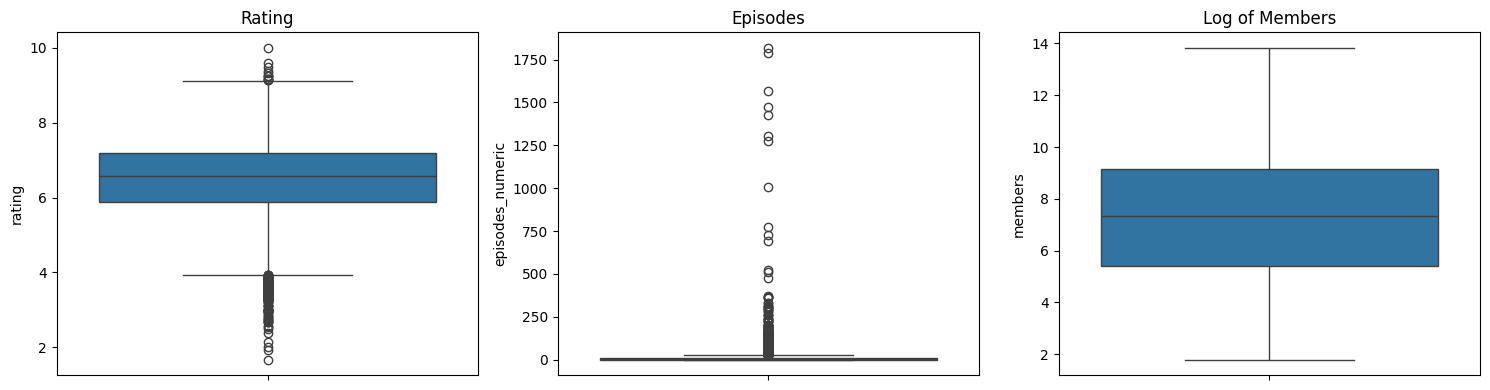

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df['rating'], ax=axes[0])
axes[0].set_title('Rating')
sns.boxplot(y=df['episodes_numeric'], ax=axes[1])
axes[1].set_title('Episodes')
sns.boxplot(y=np.log1p(df['members']), ax=axes[2])
axes[2].set_title('Log of Members')
plt.tight_layout()
plt.show()

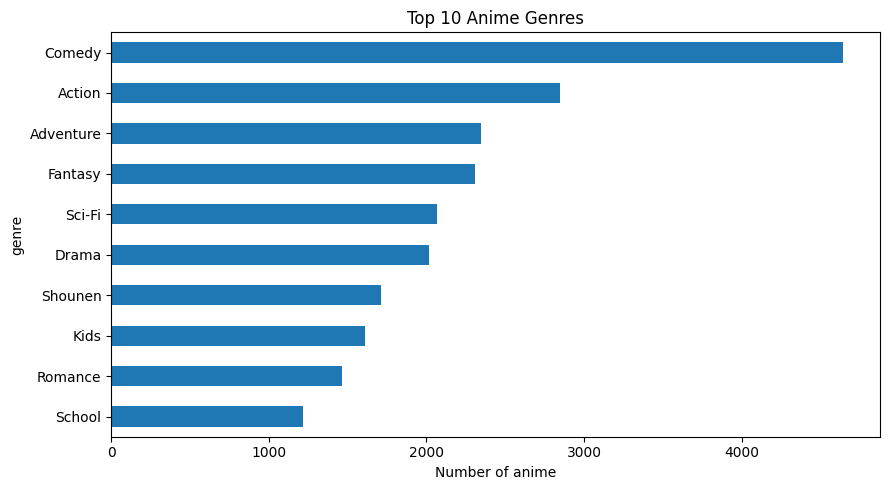

In [10]:
genre_counts = df['genre'].dropna().str.split(', ').explode().value_counts().head(10)
plt.figure(figsize=(9, 5))
genre_counts.sort_values().plot(kind='barh')
plt.title('Top 10 Anime Genres')
plt.xlabel('Number of anime')
plt.tight_layout()
plt.show()

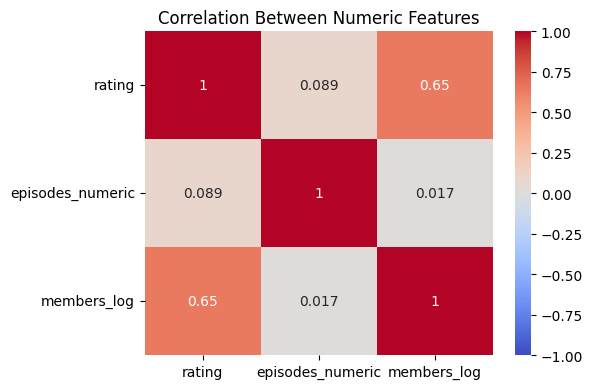

In [11]:
numeric_data = df[['rating', 'episodes_numeric', 'members']].copy()
numeric_data['members_log'] = np.log1p(numeric_data['members'])
plt.figure(figsize=(6, 4))
sns.heatmap(numeric_data[['rating', 'episodes_numeric', 'members_log']].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Between Numeric Features')
plt.tight_layout()
plt.show()

## 3. Prepare the data

In [12]:
anime = df.copy()
anime['name'] = anime['name'].map(html.unescape)
anime['genre'] = anime['genre'].fillna('Unknown')
anime['type'] = anime['type'].fillna('Unknown')
anime['episodes'] = pd.to_numeric(anime['episodes'].replace('Unknown', np.nan), errors='coerce')
anime['episodes'] = anime['episodes'].fillna(anime['episodes'].median())
anime['rating'] = anime['rating'].fillna(anime['rating'].median())
anime['members_log'] = np.log1p(anime['members'])
anime[['name', 'genre', 'type', 'episodes', 'rating', 'members']].head()

,name,genre,type,episodes,rating,members
0,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1.0,9.37,200630
1,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64.0,9.26,793665
2,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.25,114262
3,Steins;Gate,"Sci-Fi, Thriller",TV,24.0,9.17,673572
4,Gintama',"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.16,151266


In [13]:
print('Missing values after preprocessing:')
print(anime[['name', 'genre', 'type', 'episodes', 'rating', 'members']].isnull().sum())

Missing values after preprocessing:
name        0
genre       0
type        0
episodes    0
rating      0
members     0
dtype: int64


## 4. Create the feature matrix

In [14]:
genre_list = anime['genre'].apply(lambda value: [part.strip() for part in value.split(',')] if value != 'Unknown' else ['Unknown'])
genre_encoder = MultiLabelBinarizer(sparse_output=True)
genre_matrix = genre_encoder.fit_transform(genre_list)
type_matrix = pd.get_dummies(anime['type'], prefix='type', dtype=float)
numeric_features = anime[['episodes', 'rating', 'members_log']]
scaler = StandardScaler()
numeric_matrix = scaler.fit_transform(numeric_features)
feature_matrix = hstack([genre_matrix, csr_matrix(type_matrix.to_numpy(dtype=float)), csr_matrix(numeric_matrix)], format='csr')
print('Feature matrix shape:', feature_matrix.shape)

Feature matrix shape: (12294, 54)


## 5. Recommend similar anime

In [15]:
def recommend_anime(title, n=10, threshold=0.2):
    title = html.unescape(str(title)).casefold()
    matches = anime.index[anime['name'].str.casefold() == title].tolist()
    if not matches:
        raise ValueError("Anime title not found. Check the spelling with anime['name'].")
    index = matches[0]
    scores = cosine_similarity(feature_matrix[index], feature_matrix).ravel()
    scores[index] = -1
    candidate_indices = np.argsort(scores)[::-1]
    candidate_indices = [i for i in candidate_indices if scores[i] >= threshold][:n]
    recommendations = anime.loc[candidate_indices, ['anime_id', 'name', 'genre', 'type', 'episodes', 'rating', 'members']].copy()
    recommendations['similarity'] = scores[candidate_indices]
    return recommendations.reset_index(drop=True)

In [16]:
recommend_anime('Fullmetal Alchemist: Brotherhood', n=10, threshold=0.2)

,anime_id,name,genre,type,episodes,rating,members,similarity
0,121,Fullmetal Alchemist,"Action, Adventure, Comedy, Drama, Fantasy, Mag...",TV,51.0,8.33,600384,0.960238
1,18115,Magi: The Kingdom of Magic,"Action, Adventure, Fantasy, Magic, Shounen",TV,25.0,8.50,245026,0.935121
2,14513,Magi: The Labyrinth of Magic,"Action, Adventure, Fantasy, Magic, Shounen",TV,25.0,8.24,317513,0.928206
3,8086,Densetsu no Yuusha no Densetsu,"Action, Adventure, Fantasy, Magic, Shounen",TV,24.0,7.83,130689,0.907046
4,31741,Magi: Sinbad no Bouken (TV),"Action, Adventure, Fantasy, Magic, Shounen",TV,13.0,8.22,73480,0.905379
5,17265,Log Horizon,"Action, Adventure, Fantasy, Game, Magic, Shounen",TV,25.0,8.14,387100,0.893078
6,22043,Fairy Tail (2014),"Action, Adventure, Comedy, Fantasy, Magic, Sho...",TV,102.0,8.25,255076,0.891133
7,16498,Shingeki no Kyojin,"Action, Drama, Fantasy, Shounen, Super Power",TV,25.0,8.54,896229,0.884014
8,28907,"Gate: Jieitai Kanochi nite, Kaku Tatakaeri","Action, Adventure, Fantasy, Military",TV,12.0,7.97,244314,0.879445
9,31637,"Gate: Jieitai Kanochi nite, Kaku Tatakaeri 2nd...","Action, Adventure, Fantasy, Military",TV,12.0,7.97,153501,0.878843


## 6. Experiment with similarity thresholds

In [17]:
target_title = 'Fullmetal Alchemist: Brotherhood'
target_index = anime.index[anime['name'].str.casefold() == target_title.casefold()][0]
target_scores = cosine_similarity(feature_matrix[target_index], feature_matrix).ravel()
target_scores[target_index] = -1
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
threshold_results = pd.DataFrame({
    'threshold': thresholds,
    'number_of_recommendations': [int((target_scores >= value).sum()) for value in thresholds]
})
threshold_results

,threshold,number_of_recommendations
0,0.1,6229
1,0.2,5341
2,0.3,4469
3,0.4,3562
4,0.5,2478
5,0.6,1442
6,0.7,527
7,0.8,81
8,0.9,5


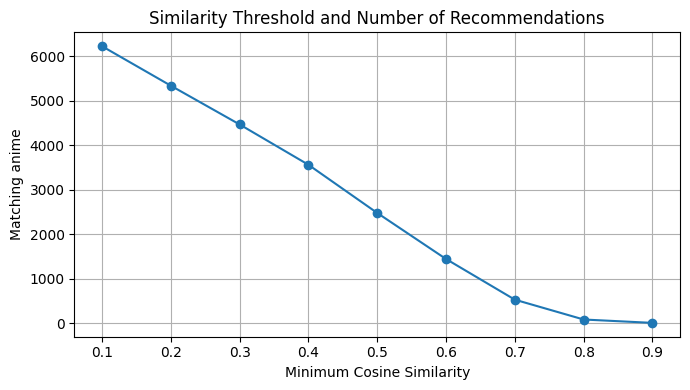

In [18]:
plt.figure(figsize=(7, 4))
plt.plot(threshold_results['threshold'], threshold_results['number_of_recommendations'], marker='o')
plt.title('Similarity Threshold and Number of Recommendations')
plt.xlabel('Minimum Cosine Similarity')
plt.ylabel('Matching anime')
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
recommend_anime('Fullmetal Alchemist: Brotherhood', n=10, threshold=0.5)

,anime_id,name,genre,type,episodes,rating,members,similarity
0,121,Fullmetal Alchemist,"Action, Adventure, Comedy, Drama, Fantasy, Mag...",TV,51.0,8.33,600384,0.960238
1,18115,Magi: The Kingdom of Magic,"Action, Adventure, Fantasy, Magic, Shounen",TV,25.0,8.50,245026,0.935121
2,14513,Magi: The Labyrinth of Magic,"Action, Adventure, Fantasy, Magic, Shounen",TV,25.0,8.24,317513,0.928206
3,8086,Densetsu no Yuusha no Densetsu,"Action, Adventure, Fantasy, Magic, Shounen",TV,24.0,7.83,130689,0.907046
4,31741,Magi: Sinbad no Bouken (TV),"Action, Adventure, Fantasy, Magic, Shounen",TV,13.0,8.22,73480,0.905379
5,17265,Log Horizon,"Action, Adventure, Fantasy, Game, Magic, Shounen",TV,25.0,8.14,387100,0.893078
6,22043,Fairy Tail (2014),"Action, Adventure, Comedy, Fantasy, Magic, Sho...",TV,102.0,8.25,255076,0.891133
7,16498,Shingeki no Kyojin,"Action, Drama, Fantasy, Shounen, Super Power",TV,25.0,8.54,896229,0.884014
8,28907,"Gate: Jieitai Kanochi nite, Kaku Tatakaeri","Action, Adventure, Fantasy, Military",TV,12.0,7.97,244314,0.879445
9,31637,"Gate: Jieitai Kanochi nite, Kaku Tatakaeri 2nd...","Action, Adventure, Fantasy, Military",TV,12.0,7.97,153501,0.878843


## 7. Review recommendation results

In [20]:
top_recommendations = recommend_anime('Fullmetal Alchemist: Brotherhood', n=10, threshold=0.2)
print('Average similarity:', round(top_recommendations['similarity'].mean(), 3))
print('Average rating of recommendations:', round(top_recommendations['rating'].mean(), 2))
print('Types in recommendations:')
print(top_recommendations['type'].value_counts())
top_recommendations[['name', 'genre', 'type', 'rating', 'similarity']]

Average similarity: 0.906
Average rating of recommendations: 8.2
Types in recommendations:
type
TV    10
Name: count, dtype: int64


,name,genre,type,rating,similarity
0,Fullmetal Alchemist,"Action, Adventure, Comedy, Drama, Fantasy, Mag...",TV,8.33,0.960238
1,Magi: The Kingdom of Magic,"Action, Adventure, Fantasy, Magic, Shounen",TV,8.50,0.935121
2,Magi: The Labyrinth of Magic,"Action, Adventure, Fantasy, Magic, Shounen",TV,8.24,0.928206
3,Densetsu no Yuusha no Densetsu,"Action, Adventure, Fantasy, Magic, Shounen",TV,7.83,0.907046
4,Magi: Sinbad no Bouken (TV),"Action, Adventure, Fantasy, Magic, Shounen",TV,8.22,0.905379
5,Log Horizon,"Action, Adventure, Fantasy, Game, Magic, Shounen",TV,8.14,0.893078
6,Fairy Tail (2014),"Action, Adventure, Comedy, Fantasy, Magic, Sho...",TV,8.25,0.891133
7,Shingeki no Kyojin,"Action, Drama, Fantasy, Shounen, Super Power",TV,8.54,0.884014
8,"Gate: Jieitai Kanochi nite, Kaku Tatakaeri","Action, Adventure, Fantasy, Military",TV,7.97,0.879445
9,"Gate: Jieitai Kanochi nite, Kaku Tatakaeri 2nd...","Action, Adventure, Fantasy, Military",TV,7.97,0.878843


## 8. Limitations and improvements

- This is a content-based recommendation system because it uses anime attributes rather than individual user viewing histories.
- Average ratings and member counts do not describe each user's personal preferences.
- Anime with missing genres may receive less useful recommendations.
- Genre-based matching can recommend titles that share tags but have different stories or styles.
- It could be improved by using user-item ratings, plot descriptions, more detailed content features, and feedback from users.